# Unit 2 — Menentukan Tujuan Teknis Data Science
**Kode unit:** J.62DMI00.002.1 · **Acuan:** SKKNI No. 299 Tahun 2020 (Ilmuwan Data) · **Proyek:** Prediksi Arah Harian IHSG

> Notebook ini menerjemahkan tujuan bisnis (Unit 1) menjadi **rumusan masalah data science**, definisi target, kriteria sukses teknis yang terukur, strategi validasi, dan lingkungan teknis. Ambang kriteria ditetapkan **sebelum** pemodelan dan dibaca ulang secara otomatis pada Unit 10 dan 11.

## 1. Dari tujuan bisnis ke tujuan teknis

| Tujuan bisnis (Unit 1) | Tujuan teknis | Keluaran teknis |
|---|---|---|
| Indikator arah harian | Klasifikasi biner dengan keluaran probabilitas $P(\text{Naik})$ | Model klasifikasi + probabilitas |
| Faktor pendorong | Analisis kepentingan fitur (*permutation importance*) pada data uji | Peringkat fitur |
| Dukungan manajemen risiko | Analisis akurasi berdasarkan tingkat keyakinan probabilitas | Aturan "zona keyakinan" |

## 2. Rumusan masalah

- **Unit observasi:** satu hari bursa BEI, dinotasikan $t$.
- **Target:** $y_t = 1$ (*Naik*) jika $\text{Close}_{IHSG}(t+1) > \text{Close}_{IHSG}(t)$, selain itu $y_t = 0$ (*Turun/Tetap*).
- **Fitur:** hanya informasi yang **sudah tersedia sebelum BEI dibuka pada $t+1$**, yaitu harga penutupan hari $t$
  dari BEI, bursa AS, komoditas, dan kurs, serta indikator makro yang sudah dipublikasikan.
- **Jenis masalah:** *supervised learning* — klasifikasi biner pada data deret waktu.

Diagram berikut menunjukkan mengapa data sesi AS hari $t$ sah dipakai sebagai fitur: sesi tersebut selesai sebelum BEI dibuka pada $t+1$.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

warnings.filterwarnings('ignore')
pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

RAW = Path('../data/raw/market_data.csv')
PROC = Path('../data/processed')
FIG = Path('../figures')
REP = Path('../reports')
MOD = Path('../models')
for p in (PROC, FIG, REP, MOD):
    p.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
EDA_END = '2022-12-31'
C_UP, C_DOWN, C_NAVY, C_ACCENT, C_GREY = '#1a9850', '#d73027', '#1f3a5f', '#e08214', '#8c8c8c'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'font.size': 10, 'axes.titleweight': 'bold',
})

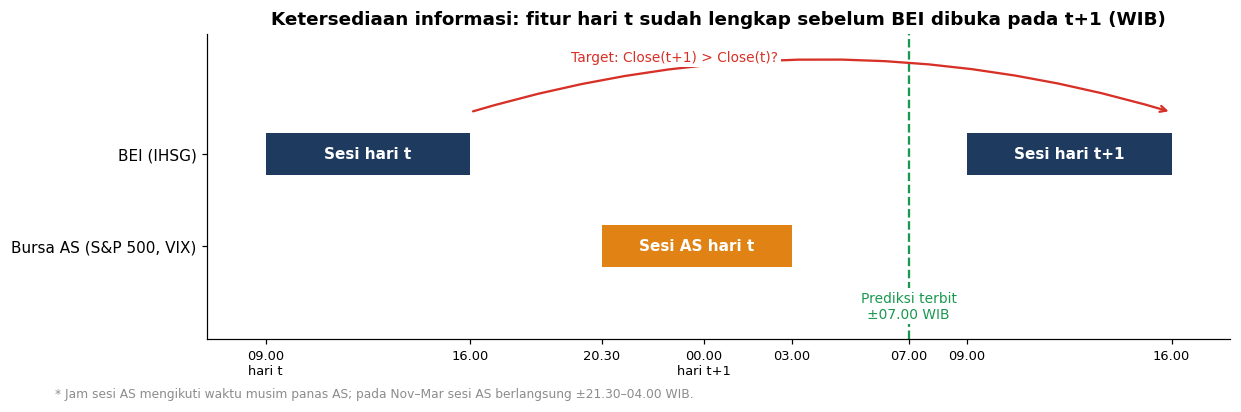

In [2]:
fig, ax = plt.subplots(figsize=(12, 3.6))
# sumbu x: jam sejak 00.00 WIB hari t
rows = {'BEI (IHSG)': 2, 'Bursa AS (S&P 500, VIX)': 1}
ax.barh(2, 16 - 9, left=9, height=0.45, color=C_NAVY)
ax.barh(2, 40 - 33, left=33, height=0.45, color=C_NAVY)
ax.barh(1, 27 - 20.5, left=20.5, height=0.45, color=C_ACCENT)
ax.text(12.5, 2, 'Sesi hari t', color='white', ha='center', va='center', fontweight='bold')
ax.text(36.5, 2, 'Sesi hari t+1', color='white', ha='center', va='center', fontweight='bold')
ax.text(23.75, 1, 'Sesi AS hari t', color='white', ha='center', va='center', fontweight='bold')
ax.axvline(31, color=C_UP, ls='--', lw=1.5)
box = dict(facecolor='white', edgecolor='none', pad=2)
ax.text(31, 0.35, 'Prediksi terbit\n±07.00 WIB', color=C_UP, ha='center', va='center', fontsize=9, bbox=box)
ax.annotate('', xy=(40, 2.45), xytext=(16, 2.45),
            arrowprops=dict(arrowstyle='->', color=C_DOWN, lw=1.5, connectionstyle='arc3,rad=-0.15'))
ax.text(23, 3.0, 'Target: Close(t+1) > Close(t)?', color=C_DOWN, ha='center', fontsize=9, bbox=box)
ax.set_yticks(list(rows.values())); ax.set_yticklabels(list(rows.keys()))
ticks = [9, 16, 20.5, 24, 27, 31, 33, 40]
labels = ['09.00\nhari t', '16.00', '20.30', '00.00\nhari t+1', '03.00', '07.00', '09.00', '16.00']
ax.set_xticks(ticks); ax.set_xticklabels(labels, fontsize=8.5)
ax.set_xlim(7, 42); ax.set_ylim(0, 3.3); ax.grid(False)
ax.set_title('Ketersediaan informasi: fitur hari t sudah lengkap sebelum BEI dibuka pada t+1 (WIB)')
fig.text(0.01, -0.04, '* Jam sesi AS mengikuti waktu musim panas AS; pada Nov–Mar sesi AS berlangsung ±21.30–04.00 WIB.',
         fontsize=8, color=C_GREY)
plt.savefig(FIG / '02_information_timeline.png')
plt.show()

## 3. Kriteria sukses teknis (ditetapkan sebelum pemodelan)

| Kode | Metrik (data uji) | Ambang | Alasan |
|---|---|---|---|
| T1 | Accuracy | ≥ 0,55 | Studi empiris prediksi arah indeks harian umumnya melaporkan akurasi sekitar 0,55–0,65 |
| T2 | F1-macro | ≥ 0,55 | Menilai kelas *Naik* dan *Turun* secara seimbang; tebakan acak ≈ 0,50 |
| T3 | ROC-AUC | ≥ 0,58 | Kemampuan membedakan kelas; 0,50 = acak |
| T4 | Mengalahkan baseline naif | Accuracy, F1-macro, dan AUC lebih tinggi daripada baseline mayoritas dan acak | Bukti nilai tambah (kriteria bisnis B1) |
| T5 | Tidak ada kebocoran data | Lolos uji *point-in-time* dan pemisahan kronologis | Hasil uji harus dapat dipercaya |

**Catatan:** ambang sengaja realistis. Pada data pasar keuangan nyata, akurasi di atas 0,70 untuk arah harian justru patut dicurigai sebagai kebocoran data.

## 4. Strategi validasi

1. **Holdout kronologis:** 80% hari bursa paling awal untuk data latih, 20% terakhir untuk data uji. **Tanpa pengacakan.**
2. **`TimeSeriesSplit` (5 lipatan)** di dalam data latih untuk membandingkan skenario model dan *tuning*.
3. **Data uji hanya dipakai satu kali** di Unit 10, setelah model final dipilih.
4. Analisis eksplorasi yang memengaruhi desain fitur hanya memakai periode **2010–2022** (bagian dari data latih).

## 5. Kandidat teknik

- **Baseline:** kelas mayoritas, tebakan acak berstrata, dan heuristik domain "ikuti arah S&P 500 semalam".
- **Model:** Logistic Regression, Decision Tree, Random Forest, Gradient Boosting, dan SVM (kernel RBF).

In [3]:
import sys, sklearn, matplotlib

technical_objective = {
    'jenis_masalah': 'Klasifikasi biner (deret waktu)',
    'unit_observasi': 'Satu hari bursa BEI (t)',
    'target': {'nama': 'y', 'definisi': 'y=1 (Naik) jika Close_IHSG(t+1) > Close_IHSG(t), selain itu 0 (Turun/Tetap)'},
    'aturan_fitur': 'Hanya data yang tersedia sebelum BEI dibuka pada t+1 (point-in-time)',
    'kpi': {
        'T1_accuracy_min': 0.55,
        'T2_f1_macro_min': 0.55,
        'T3_roc_auc_min': 0.58,
        'T4_kalahkan_baseline': ['Mayoritas', 'Acak berstrata'],
        'T5_tanpa_kebocoran': True,
    },
    'validasi': {'holdout': 'kronologis 80/20', 'cv': 'TimeSeriesSplit(n_splits=5)', 'eda_end': EDA_END},
    'kandidat_model': ['Logistic Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'SVM (RBF)'],
    'baseline': ['Mayoritas', 'Acak berstrata', 'Ikuti arah S&P 500'],
    'lingkungan': {'python': sys.version.split()[0], 'pandas': pd.__version__, 'numpy': np.__version__,
                   'scikit_learn': sklearn.__version__, 'matplotlib': matplotlib.__version__},
}
with open(REP / 'technical_objective.json', 'w', encoding='utf-8') as f:
    json.dump(technical_objective, f, ensure_ascii=False, indent=2)

kpi = pd.DataFrame([
    ('T1', 'Accuracy', technical_objective['kpi']['T1_accuracy_min']),
    ('T2', 'F1-macro', technical_objective['kpi']['T2_f1_macro_min']),
    ('T3', 'ROC-AUC', technical_objective['kpi']['T3_roc_auc_min']),
], columns=['Kode', 'Metrik', 'Ambang minimum'])
display(kpi)
print('Lingkungan teknis:', technical_objective['lingkungan'])
print('Tersimpan ->', REP / 'technical_objective.json')

,Kode,Metrik,Ambang minimum
0,T1,Accuracy,0.5500
1,T2,F1-macro,0.5500
2,T3,ROC-AUC,0.5800


Lingkungan teknis: {'python': '3.9.6', 'pandas': '2.3.3', 'numpy': '2.0.2', 'scikit_learn': '1.6.1', 'matplotlib': '3.9.4'}
Tersimpan -> ../reports/technical_objective.json


## Ringkasan Unit 2

- Masalah dirumuskan sebagai **klasifikasi biner** arah IHSG hari bursa berikutnya, dengan aturan *point-in-time* yang tegas.
- Lima kriteria sukses teknis (T1–T5) ditetapkan **sebelum** melihat hasil model dan disimpan di `reports/technical_objective.json`.
- Strategi validasi menghormati urutan waktu: holdout kronologis + `TimeSeriesSplit`.